# Assignment Beta, Question 2: LoRA vs QLoRA vs DoRA vs AdaLoRA for tool calling
**Student ID:** 23K-0001  |  **Base model:** Qwen2.5-1.5B-Instruct  |  **Hardware:** Colab free T4 (fp16, no bf16)

In [3]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [4]:
!pip install -q -U peft bitsandbytes datasets accelerate transformers

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os, re, json, gc, time, random, math
import numpy as np, pandas as pd, torch
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, AutoConfig, BitsAndBytesConfig,
                          TrainingArguments, Trainer, TrainerCallback, set_seed)
from peft import LoraConfig, AdaLoraConfig, get_peft_model, prepare_model_for_kbit_training

from google.colab import drive
drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/Assignment_Beta_Q2"
os.makedirs(OUT, exist_ok=True)

STUDENT_ID = "23K-0001"
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
SEED = 42
N_TOTAL, N_TEST = 2000, 200
MAX_LEN = 512
EPOCHS, LR, BS, GA = 2, 2e-4, 2, 8
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]   # same for every method
DTYPE = torch.float16                                  # T4 has no bf16
assert torch.cuda.is_available(), "Switch the runtime to a T4 GPU"
print(torch.cuda.get_device_name(0))

Mounted at /content/drive
Tesla T4


## Section 1: LoRA theory  (W0 is 4096 x 4096, r = 16)

**(a) Trainable parameters.** LoRA learns dW = B A with B in R^(4096x16) and A in R^(16x4096).
- A: 16 x 4096 = 65,536
- B: 4096 x 16 = 65,536
- Total = 2 x 4096 x 16 = **131,072** trainable parameters.

**(b) Percentage.** W0 has 4096 x 4096 = 16,777,216 parameters.
131,072 / 16,777,216 = **0.78125 %** (equivalently 2r/d = 32/4096).

**(c) Why B = 0 and A random?**
- With B = 0, dW = BA = 0, so at step 0 the adapted model is *exactly* the pretrained model. Training starts from the pretrained behaviour instead of from a perturbed one.
- B = 0 does not stop learning: the gradient w.r.t. B is (dL/dh)(A x)^T, which is non-zero because A is random. So B moves away from zero on the first step, and A then starts receiving gradient too (its gradient is proportional to B).
- A random breaks symmetry between the r rank components. If **both were zero**, both gradients would be zero (each is proportional to the other) and nothing would ever train. If **both were random**, dW = BA would be a non-zero random matrix on step 1, injecting noise into every adapted layer, so the very first forward pass is already a damaged version of the pretrained model, the loss spikes, and early updates are spent repairing that noise (it can hurt pretrained knowledge and destabilise training).

**(d) What each variant solves that plain LoRA does not**
- **QLoRA, memory.** LoRA still keeps the frozen base weights in 16-bit, which dominates GPU memory. QLoRA stores the frozen base in **4-bit NF4** (NormalFloat: quantisation levels placed at quantiles of a normal distribution, which suits roughly Gaussian pretrained weights, so it loses less information than uniform 4-bit), plus **double quantisation** (the quantisation constants are themselves quantised) and **paged optimizers** (optimizer state is paged between GPU and CPU memory so sudden memory spikes, for example from long batches, do not cause out-of-memory crashes). Adapters and compute stay in 16-bit.
- **DoRA, learning quality at low rank.** In plain LoRA, magnitude and direction of a weight change are entangled in one low-rank update, and its learning pattern differs from full fine-tuning. DoRA splits each weight into **magnitude** (a learned vector, per column) and **direction** (the normalised matrix), applies LoRA only to the direction, and trains the magnitude separately. This tends to give better accuracy and stability than LoRA at the same rank, at the cost of extra training compute/memory for the norm computation.
- **AdaLoRA, where the rank is spent.** LoRA gives every matrix the same rank, even though some layers need far more capacity than others. AdaLoRA writes dW in an SVD-like form (P, singular values, Q) with an orthogonality penalty, scores each singular value by importance (sensitivity), and **prunes the low-importance ones under a global rank budget**, so rank ends up where it is actually needed.

In [3]:
d, r = 4096, 16
A = r * d; B = d * r
print("A:", A, "B:", B, "total:", A + B)
print("W0:", d * d, " percent:", 100 * (A + B) / (d * d))

A: 65536 B: 65536 total: 131072
W0: 16777216  percent: 0.78125


## Section 2: data (2,000 glaive examples, 200 held-out test)
Each example: system prompt listing the available functions + the customer's first message -> target = a single JSON object `{"name":..., "arguments":{...}}`.
Only examples whose first assistant turn is a function call are kept, and each is at most 512 tokens (so no target is ever truncated).
The last 200 are the test set and are never used in training.

In [4]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
INSTR = ('Reply with ONLY one JSON object of the form {"name": <function name>, "arguments": {...}} '
         'and nothing else. Use only the functions listed above.')

def parse_call(txt):
    body = txt.replace("<functioncall>", "").strip()
    try:
        obj = json.loads(body)
        name, a = obj.get("name"), obj.get("arguments")
    except Exception:
        m = re.search(r'"name":\s*"([^"]+)"\s*,\s*"arguments":\s*\x27(.*)\x27\s*\}\s*$', body, re.S)
        if not m: return None
        name, a = m.group(1), m.group(2)
    if isinstance(a, str):
        try: a = json.loads(a)
        except Exception: return None
    if not isinstance(name, str) or not isinstance(a, dict): return None
    return name, a

data_path = f"{OUT}/data.json"
if os.path.exists(data_path): os.remove(data_path)   # delete the empty cache

ds = load_dataset("glaiveai/glaive-function-calling-v2", split="train").shuffle(seed=SEED).select(range(20000))
print(repr(ds[0]["chat"][:400]))   # so we can see the real format

rows = []
for ex in ds:
    parts = ex["chat"].split("\n\n\n")
    if len(parts) < 2: continue
    mu = re.match(r"USER:\s*(.*)", parts[0], re.S)
    ma = re.match(r"(?:ASSISTANT|A):\s*(<functioncall>.*)", parts[1], re.S)
    if not mu or not ma: continue
    call = parse_call(ma.group(1).replace("<|endoftext|>", "").strip())
    if call is None: continue
    name, args = call
    sys_txt = ex["system"].replace("SYSTEM:", "", 1).strip()
    user = mu.group(1).strip()
    prompt = tok.apply_chat_template(
        [{"role": "system", "content": sys_txt + "\n\n" + INSTR}, {"role": "user", "content": user}],
        tokenize=False, add_generation_prompt=True)
    target = json.dumps({"name": name, "arguments": args}, ensure_ascii=False)
    if len(tok(prompt + target + tok.eos_token)["input_ids"]) > MAX_LEN: continue
    rows.append(dict(sys=sys_txt, user=user, prompt=prompt, target=target, name=name, args=args))
    if len(rows) == N_TOTAL: break

assert len(rows) == N_TOTAL, f"only {len(rows)} usable rows, send me the printed chat sample"
json.dump(rows, open(data_path, "w"))

train_rows, test_rows = rows[:N_TOTAL - N_TEST], rows[N_TOTAL - N_TEST:]
print(len(train_rows), "train /", len(test_rows), "test")
print(test_rows[0]["user"], "->", test_rows[0]["target"])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/106 [00:00<?, ?B/s]

glaive-function-calling-v2.json: reconstructing file:   0%|          |  0.00B /  271MB            

glaive-function-calling-v2.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/112960 [00:00<?, ? examples/s]

"USER: Can you please book a flight for me from New York to Los Angeles?\n\n\nASSISTANT: I'm sorry, but I'm unable to assist with booking flights. My current capabilities allow me to calculate the distance between two locations. However, I don't have the function to book flights or perform other external tasks. <|endoftext|>\n\n\n"
1800 train / 200 test
Hi, can you tell me how old I am? My birthdate is 1990-05-15. -> {"name": "calculate_age", "arguments": {"birthdate": "1990-05-15"}}


In [5]:
class DS(torch.utils.data.Dataset):
    def __init__(self, rs):
        self.items = []
        for r_ in rs:
            p = tok(r_["prompt"], add_special_tokens=False)["input_ids"]
            t = tok(r_["target"] + tok.eos_token, add_special_tokens=False)["input_ids"]
            self.items.append((p + t, [-100] * len(p) + t))   # loss only on the JSON answer
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        ids, lab = self.items[i]
        return {"input_ids": ids, "labels": lab}

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id); lab = torch.full((len(batch), L), -100)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"]); lab[i, :n] = torch.tensor(b["labels"]); att[i, :n] = 1
    return {"input_ids": ids, "labels": lab, "attention_mask": att}

train_ds = DS(train_rows)
STEPS_PER_EPOCH = math.ceil(len(train_ds) / (BS * GA))
TOTAL_STEPS = STEPS_PER_EPOCH * EPOCHS
print("optimizer steps:", TOTAL_STEPS)

@torch.no_grad()
def evaluate(model, rs, bs=8):
    model.eval(); tok.padding_side = "left"
    outs, t0 = [], time.time()
    for i in range(0, len(rs), bs):
        enc = tok([x["prompt"] for x in rs[i:i + bs]], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        gen = model.generate(**enc, max_new_tokens=160, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += [tok.decode(g, skip_special_tokens=True).strip() for g in gen[:, enc["input_ids"].shape[1]:]]
    sec = time.time() - t0
    valid = tool = full = lenient = 0
    for x, o in zip(rs, outs):
        try:
            obj = json.loads(o); valid += 1
            if isinstance(obj, dict) and obj.get("name") == x["name"]:
                tool += 1
                if obj.get("arguments") == x["args"]: full += 1
        except Exception:
            pass
        try:   # lenient: pull the first {...} out of surrounding text (diagnostic only)
            obj2 = json.loads(o[o.index("{"): o.rindex("}") + 1])
            if isinstance(obj2, dict) and obj2.get("name") == x["name"]: lenient += 1
        except Exception:
            pass
    return dict(json_valid=valid, tool_acc=tool, full_match=full, tool_lenient=lenient, eval_sec=sec), outs

optimizer steps: 226


In [6]:
def load_base(quant=False):
    kw = dict(torch_dtype=DTYPE, device_map={"": 0})
    if quant:
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, **kw)

with torch.device("meta"):
    BASE_PARAMS = sum(p.numel() for p in AutoModelForCausalLM.from_config(AutoConfig.from_pretrained(MODEL_ID)).parameters())
print("base params:", BASE_PARAMS)

def make_peft(method, r):
    common = dict(lora_alpha=2 * r, lora_dropout=0.05, target_modules=TARGETS, task_type="CAUSAL_LM")
    if method in ("lora", "qlora"): return LoraConfig(r=r, **common)
    if method == "dora":           return LoraConfig(r=r, use_dora=True, **common)
    if method == "adalora":
        return AdaLoraConfig(init_r=int(round(1.5 * r)), target_r=r, tinit=20, tfinal=50, deltaT=10,
                             total_step=TOTAL_STEPS, **common)

class AdaCB(TrainerCallback):   # AdaLoRA must re-allocate ranks every step, after backward
    def on_pre_optimizer_step(self, args, state, control, model=None, **kw):
        model.base_model.update_and_allocate(state.global_step)

def cleanup():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def run_base():
    p = f"{OUT}/base.json"
    if os.path.exists(p): return json.load(open(p))
    cleanup(); m = load_base(); m.config.use_cache = True
    met, outs = evaluate(m, test_rows)
    res = dict(method="base", r=0, trainable=0, trainable_pct=0.0, peak_gb=None, train_min=0.0, merged_eval_sec=None, outputs=outs, **met)
    json.dump(res, open(p, "w")); del m; cleanup(); return res

def run_method(method, r=8):
    tag = f"{method}_r{r}"; p = f"{OUT}/{tag}.json"
    if os.path.exists(p):
        print("skip (done):", tag); return json.load(open(p))
    cleanup(); set_seed(SEED)
    model = load_base(quant=(method == "qlora"))
    if method == "qlora":
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)
    model = get_peft_model(model, make_peft(method, r))
    for q in model.parameters():
        if q.requires_grad: q.data = q.data.float()      # fp16 AMP needs fp32 trainable weights
    trainable = sum(q.numel() for q in model.parameters() if q.requires_grad)
    model.config.use_cache = False
    args = TrainingArguments(output_dir=f"/content/tmp_{tag}", per_device_train_batch_size=BS,
        gradient_accumulation_steps=GA, num_train_epochs=EPOCHS, learning_rate=LR, lr_scheduler_type="cosine",
        warmup_steps=max(1, round(0.05 * TOTAL_STEPS)), fp16=True, logging_steps=20, save_strategy="no", report_to="none",
        seed=SEED, data_seed=SEED, optim="adamw_torch", remove_unused_columns=False, dataloader_num_workers=0)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=collate,
                      callbacks=[AdaCB()] if method == "adalora" else [])
    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_allocated() / 2**30
    model.save_pretrained(f"{OUT}/{tag}_adapter")
    model.config.use_cache = True
    met, outs = evaluate(model, test_rows)
    merged_sec = None
    if method in ("lora", "dora") and r == 8:      # merged adapter = plain weights, no extra inference cost
        merged = model.merge_and_unload()
        merged_sec = evaluate(merged, test_rows)[0]["eval_sec"]
    res = dict(method=method, r=r, trainable=trainable, trainable_pct=100 * trainable / BASE_PARAMS,
               peak_gb=peak, train_min=train_min, merged_eval_sec=merged_sec, outputs=outs, **met)
    json.dump(res, open(p, "w"))
    del model, trainer; cleanup(); return res

base params: 1543714304


## Run all five rows  (base, LoRA, QLoRA, DoRA, AdaLoRA at r = 8; AdaLoRA starts at 12)
Run each in its own cell so a disconnect only costs one run.

In [7]:
base_res = run_base(); print({k: v for k, v in base_res.items() if k != "outputs"})

{'method': 'base', 'r': 0, 'trainable': 0, 'trainable_pct': 0.0, 'peak_gb': None, 'train_min': 0.0, 'merged_eval_sec': None, 'json_valid': 200, 'tool_acc': 200, 'full_match': 190, 'tool_lenient': 200, 'eval_sec': 68.4785578250885}


In [8]:
lora_res = run_method("lora", 8); print({k: v for k, v in lora_res.items() if k != "outputs"})

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
20,0.011350
40,0.006012
60,0.004555
80,0.005762
100,0.004500
120,0.006651
140,0.002790
160,0.002277
180,0.002570
200,0.003227


{'method': 'lora', 'r': 8, 'trainable': 2179072, 'trainable_pct': 0.1411577255165474, 'peak_gb': 7.311313629150391, 'train_min': 10.366134762763977, 'merged_eval_sec': 62.536805391311646, 'json_valid': 200, 'tool_acc': 200, 'full_match': 195, 'tool_lenient': 200, 'eval_sec': 92.62282609939575}


In [9]:
qlora_res = run_method("qlora", 8); print({k: v for k, v in qlora_res.items() if k != "outputs"})

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
20,0.015123
40,0.005911
60,0.004668
80,0.006156
100,0.004845
120,0.007202
140,0.002765
160,0.002162
180,0.002540
200,0.003541


{'method': 'qlora', 'r': 8, 'trainable': 2179072, 'trainable_pct': 0.1411577255165474, 'peak_gb': 7.773961067199707, 'train_min': 13.486245739459992, 'merged_eval_sec': None, 'json_valid': 200, 'tool_acc': 200, 'full_match': 196, 'tool_lenient': 200, 'eval_sec': 137.48767495155334}


In [8]:
dora_res = run_method("dora", 8); print({k: v for k, v in dora_res.items() if k != "outputs"})

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Step,Training Loss
20,0.011284
40,0.006011
60,0.004512
80,0.005755
100,0.004503
120,0.006640
140,0.002770
160,0.002235
180,0.002559
200,0.003111


{'method': 'dora', 'r': 8, 'trainable': 2279424, 'trainable_pct': 0.14765841024428314, 'peak_gb': 7.983584403991699, 'train_min': 13.218712457021077, 'merged_eval_sec': 61.338584661483765, 'json_valid': 200, 'tool_acc': 200, 'full_match': 195, 'tool_lenient': 200, 'eval_sec': 144.68956446647644}


In [9]:
adalora_res = run_method("adalora", 8); print({k: v for k, v in adalora_res.items() if k != "outputs"})

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
20,6.634211
40,4.255550
60,3.007985
80,2.643979
100,2.393023
120,2.139879
140,2.020411
160,1.893028
180,1.809495
200,1.765013


{'method': 'adalora', 'r': 8, 'trainable': 3270064, 'trainable_pct': 0.21183090624520118, 'peak_gb': 7.579929351806641, 'train_min': 13.705253386497498, 'merged_eval_sec': None, 'json_valid': 200, 'tool_acc': 200, 'full_match': 190, 'tool_lenient': 200, 'eval_sec': 99.60507607460022}


In [10]:
def load_all(rs_only=None):
    out = []
    for f in sorted(os.listdir(OUT)):
        if f.endswith(".json") and f != "data.json":
            out.append(json.load(open(f"{OUT}/{f}")))
    return out

allres = load_all()
tbl = pd.DataFrame([{k: v for k, v in x.items() if k != "outputs"} for x in allres])
main = tbl[tbl.r.isin([0, 8])].copy()
order = {"base": 0, "lora": 1, "qlora": 2, "dora": 3, "adalora": 4}
main = main.sort_values("method", key=lambda s: s.map(order))
main["tool_acc_%"] = main.tool_acc / 2; main["json_valid_%"] = main.json_valid / 2; main["full_match_%"] = main.full_match / 2
cols = ["method", "trainable", "trainable_pct", "peak_gb", "train_min", "json_valid", "tool_acc", "full_match",
        "tool_lenient", "eval_sec", "merged_eval_sec"]
print("(counts are out of 200)")
display(main[cols].round(3))
main[cols].to_csv(f"{OUT}/results_table.csv", index=False)

(counts are out of 200)


,method,trainable,trainable_pct,peak_gb,train_min,json_valid,tool_acc,full_match,tool_lenient,eval_sec,merged_eval_sec
1,base,0,0.000,NaN,0.000,200,200,190,200,68.479,NaN
3,lora,2179072,0.141,7.311,10.366,200,200,195,200,92.623,62.537
4,qlora,2179072,0.141,7.774,13.486,200,200,196,200,137.488,NaN
2,dora,2279424,0.148,7.984,13.219,200,200,195,200,144.690,61.339
0,adalora,3270064,0.212,7.580,13.705,200,200,190,200,99.605,NaN


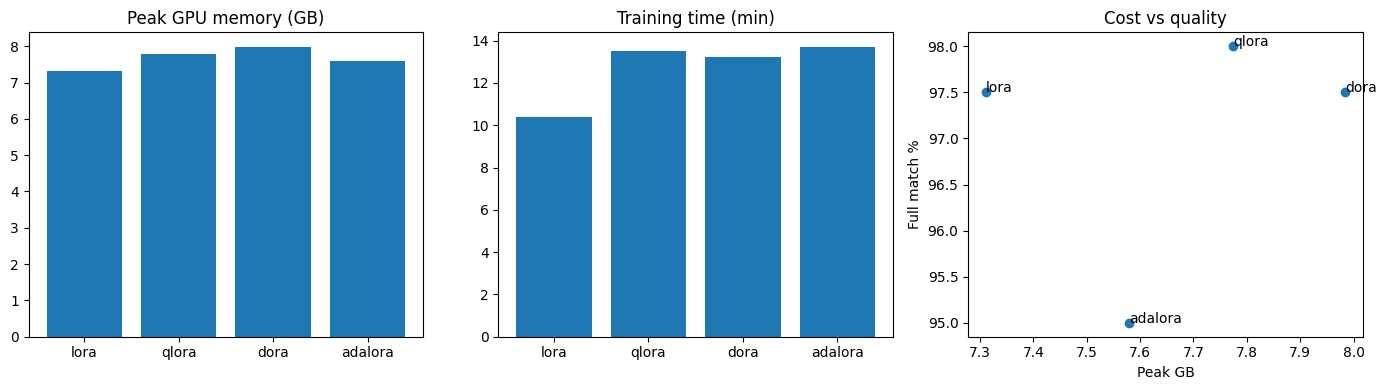

In [11]:
import matplotlib.pyplot as plt
m = main[main.method != "base"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].bar(m.method, m.peak_gb); ax[0].set_title("Peak GPU memory (GB)")
ax[1].bar(m.method, m.train_min); ax[1].set_title("Training time (min)")
ax[2].scatter(m.peak_gb, m.full_match / 2)
for _, x in m.iterrows(): ax[2].annotate(x.method, (x.peak_gb, x.full_match / 2))
ax[2].set_xlabel("Peak GB"); ax[2].set_ylabel("Full match %"); ax[2].set_title("Cost vs quality")
plt.tight_layout(); plt.savefig(f"{OUT}/cost_plot.png", dpi=150); plt.show()

## Section 3: is a bigger rank better?
Takes the best of the four methods (highest full match, ties broken by tool accuracy) and trains it at r = 4, 16, 32. (r = 8 is already done.)
`lora_alpha = 2r` throughout, so the LoRA scale stays constant across ranks.

In [12]:
four = main[main.method.isin(["lora", "qlora", "dora", "adalora"])]
best = four.sort_values(["full_match", "tool_acc"], ascending=False).iloc[0].method
print("best method:", best)
for r_ in (4, 16, 32):
    res = run_method(best, r_); print(r_, {k: v for k, v in res.items() if k != "outputs"})

best method: qlora


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
20,0.016071
40,0.005952
60,0.004760
80,0.006275
100,0.004940
120,0.007593
140,0.002997
160,0.002511
180,0.002795
200,0.004301


4 {'method': 'qlora', 'r': 4, 'trainable': 1089536, 'trainable_pct': 0.0705788627582737, 'peak_gb': 7.757026672363281, 'train_min': 13.258428931236267, 'merged_eval_sec': None, 'json_valid': 200, 'tool_acc': 200, 'full_match': 194, 'tool_lenient': 200, 'eval_sec': 135.11529350280762}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
20,0.014588
40,0.006007
60,0.005061
80,0.006275
100,0.004959
120,0.006792
140,0.002553
160,0.001963
180,0.002474
200,0.002725


16 {'method': 'qlora', 'r': 16, 'trainable': 4358144, 'trainable_pct': 0.2823154510330948, 'peak_gb': 7.814281463623047, 'train_min': 13.10554297765096, 'merged_eval_sec': None, 'json_valid': 200, 'tool_acc': 200, 'full_match': 196, 'tool_lenient': 200, 'eval_sec': 130.99156260490417}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
20,0.014337
40,0.005943
60,0.005840
80,0.007122
100,0.005399
120,0.006531
140,0.002359
160,0.002134
180,0.002697
200,0.002130


32 {'method': 'qlora', 'r': 32, 'trainable': 8716288, 'trainable_pct': 0.5646309020661896, 'peak_gb': 7.890621185302734, 'train_min': 13.133105039596558, 'merged_eval_sec': None, 'json_valid': 200, 'tool_acc': 200, 'full_match': 196, 'tool_lenient': 200, 'eval_sec': 129.53712725639343}


,r,trainable,peak_gb,train_min,json_valid,tool_acc,full_match,tool_acc_%
2,4,1089536,7.757,13.258,200,200,194,100.0
3,8,2179072,7.774,13.486,200,200,196,100.0
0,16,4358144,7.814,13.106,200,200,196,100.0
1,32,8716288,7.891,13.133,200,200,196,100.0


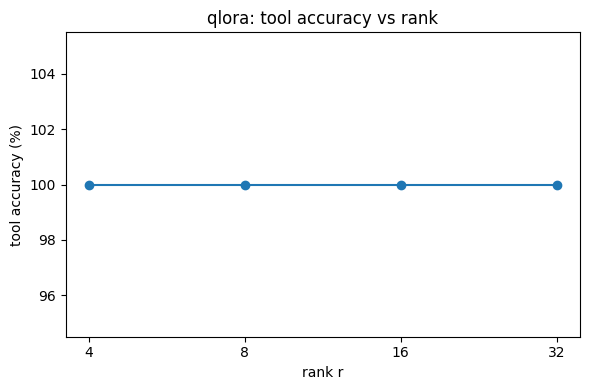

In [13]:
sw = pd.DataFrame([{k: v for k, v in x.items() if k != "outputs"} for x in load_all() if x["method"] == best]).sort_values("r")
sw["tool_acc_%"] = sw.tool_acc / 2
display(sw[["r", "trainable", "peak_gb", "train_min", "json_valid", "tool_acc", "full_match", "tool_acc_%"]].round(3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sw.r, sw["tool_acc_%"], marker="o"); ax.set_xscale("log", base=2); ax.set_xticks(sw.r); ax.set_xticklabels(sw.r)
ax.set_xlabel("rank r"); ax.set_ylabel("tool accuracy (%)"); ax.set_title(f"{best}: tool accuracy vs rank")
plt.tight_layout(); plt.savefig(f"{OUT}/rank_plot.png", dpi=150); plt.show()

## Section 4 helper: five failures of the best model
Labels are assigned automatically (broken JSON / refused-no-call / made-up function / wrong tool / made-up argument / wrong or missing argument value). Read them yourself before putting them in the report.

In [14]:
def label_error(x, o):
    try: obj = json.loads(o)
    except Exception: return "refused / no call" if "{" not in o else "broken JSON"
    if not isinstance(obj, dict) or "name" not in obj: return "something else"
    allowed = set(re.findall(r'"name":\s*"([^"]+)"', x["sys"]))
    if obj["name"] not in allowed: return "made-up function"
    if obj["name"] != x["name"]: return "wrong tool"
    pa = obj.get("arguments")
    if not isinstance(pa, dict): return "something else"
    if set(pa) - set(x["args"]): return "made-up argument"
    return "wrong/missing argument value"

best_res = json.load(open(f"{OUT}/{best}_r8.json"))
wrong = []
for x, o in zip(test_rows, best_res["outputs"]):
    try: ok = json.loads(o) == {"name": x["name"], "arguments": x["args"]}
    except Exception: ok = False
    if not ok: wrong.append((x, o))
print(len(wrong), "wrong of 200")
random.Random(0).shuffle(wrong)
from collections import Counter
print(Counter(label_error(x, o) for x, o in wrong))
for x, o in wrong[:5]:
    print("-" * 70); print("CUSTOMER :", x["user"]); print("CORRECT  :", x["target"])
    print("MODEL    :", o); print("LABEL    :", label_error(x, o))

4 wrong of 200
Counter({'wrong/missing argument value': 3, 'made-up argument': 1})
----------------------------------------------------------------------
CUSTOMER : I am looking for movies with Tom Hanks.
CORRECT  : {"name": "search_movies", "arguments": {"keyword": "Tom Hanks"}}
MODEL    : {"name": "search_movies", "arguments": {"actors": ["Tom Hanks"]}}
LABEL    : made-up argument
----------------------------------------------------------------------
CUSTOMER : I need to create a task named "Buy groceries" that is due tomorrow.
CORRECT  : {"name": "create_task", "arguments": {"task_name": "Buy groceries", "due_date": "2022-05-15"}}
MODEL    : {"name": "create_task", "arguments": {"task_name": "Buy groceries", "due_date": "2022-12-31"}}
LABEL    : wrong/missing argument value
----------------------------------------------------------------------
CUSTOMER : I am looking for a book but I can't remember the exact title. I know it's a mystery novel by Agatha Christie and it was published 